In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("Dataset/raw_dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,Name,Age,Salary,Join_Date,Department
0,Pam,25.0,70200.0,1/15/2023,HR
1,Jane,NaN,65000.0,8/1/2022,Finance
2,Alice,22.0,71350.0,5/20/2021,HR
3,Bob,22.0,NaN,1/15/2023,IT
4,Pam,25.0,71250.0,1/15/2023,HR


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 43
Number of columns: 5


In [5]:
df.columns

Index(['Name', 'Age', 'Salary', 'Join_Date', 'Department'], dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43 entries, 0 to 42
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Name        43 non-null     object 
 1   Age         39 non-null     float64
 2   Salary      36 non-null     float64
 3   Join_Date   43 non-null     object 
 4   Department  43 non-null     object 
dtypes: float64(2), object(3)
memory usage: 1.8+ KB


In [7]:
df.isnull().sum()

Name          0
Age           4
Salary        7
Join_Date     0
Department    0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(1)

In [9]:
df.describe()

,Age,Salary
count,39.000000,36.000000
mean,34.692308,132729.694444
std,9.624951,196694.464572
min,21.000000,61000.000000
25%,25.000000,66175.000000
50%,36.000000,71841.000000
75%,42.000000,77421.000000
max,57.000000,921000.000000


In [10]:
Q1 = df["Salary"].quantile(0.25)
Q3 = df["Salary"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Q1: 66175.0
Q3: 77421.0
IQR: 11246.0
Lower limit: 49306.0
Upper limit: 94290.0


In [11]:
salary_outliers = df[
    (df["Salary"] < lower_limit) |
    (df["Salary"] > upper_limit)
]

salary_outliers[["Name", "Salary"]]

,Name,Salary
6,Joanne,120000.0
15,Susy,126001.0
18,Joanne,125600.0
21,Norma,921000.0
28,Jenny,801423.0
42,Kim,546222.0


In [12]:
df["Salary"] = df["Salary"].clip(
    lower=lower_limit,
    upper=upper_limit
)

print("Salary outliers have been capped.")

Salary outliers have been capped.


In [13]:
df.isnull().sum()

Name          0
Age           4
Salary        7
Join_Date     0
Department    0
dtype: int64

In [14]:
age_median = df["Age"].median()

print("Median Age:", age_median)

Median Age: 36.0


In [15]:
df["Age"] = df["Age"].fillna(age_median)

print("Missing Age values after cleaning:", df["Age"].isnull().sum())

Missing Age values after cleaning: 0


In [16]:
salary_median = df["Salary"].median()

print("Median Salary:", salary_median)

Median Salary: 71841.0


In [17]:
df["Salary"] = df["Salary"].fillna(salary_median)

print("Missing Salary values after cleaning:", df["Salary"].isnull().sum())

Missing Salary values after cleaning: 0


In [18]:
print("Duplicates before cleaning:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after cleaning:", df.duplicated().sum())

Duplicates before cleaning: 2
Duplicates after cleaning: 0


In [19]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
Name          0
Age           0
Salary        0
Join_Date     0
Department    0
dtype: int64

Duplicate rows:
0


In [20]:
print(df["Join_Date"].dtype)

object


In [21]:
df["Join_Date"] = pd.to_datetime(df["Join_Date"])

print("Join_Date data type:", df["Join_Date"].dtype)

Join_Date data type: datetime64[ns]


In [22]:
df["Join_Year"] = df["Join_Date"].dt.year

print(df[["Join_Date", "Join_Year"]].head())

   Join_Date  Join_Year
0 2023-01-15       2023
1 2022-08-01       2022
2 2021-05-20       2021
3 2023-01-15       2023
4 2023-01-15       2023


In [23]:
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[0, 25, 35, 45, 100],
    labels=["18-25", "26-35", "36-45", "46+"]
)

print(df[["Age", "Age_Group"]].head())

    Age Age_Group
0  25.0     18-25
1  36.0     36-45
2  22.0     18-25
3  22.0     18-25
4  25.0     18-25


In [24]:
df.head()

,Name,Age,Salary,Join_Date,Department,Join_Year,Age_Group
0,Pam,25.0,70200.0,2023-01-15,HR,2023,18-25
1,Jane,36.0,65000.0,2022-08-01,Finance,2022,36-45
2,Alice,22.0,71350.0,2021-05-20,HR,2021,18-25
3,Bob,22.0,71841.0,2023-01-15,IT,2023,18-25
4,Pam,25.0,71250.0,2023-01-15,HR,2023,18-25


In [25]:
df.head()

,Name,Age,Salary,Join_Date,Department,Join_Year,Age_Group
0,Pam,25.0,70200.0,2023-01-15,HR,2023,18-25
1,Jane,36.0,65000.0,2022-08-01,Finance,2022,36-45
2,Alice,22.0,71350.0,2021-05-20,HR,2021,18-25
3,Bob,22.0,71841.0,2023-01-15,IT,2023,18-25
4,Pam,25.0,71250.0,2023-01-15,HR,2023,18-25


In [26]:
df.dtypes

Name                  object
Age                  float64
Salary               float64
Join_Date     datetime64[ns]
Department            object
Join_Year              int32
Age_Group           category
dtype: object

In [27]:
df.shape

(41, 7)

In [28]:
print("Current rows:", len(df))
print("Current columns:", len(df.columns))

Current rows: 41
Current columns: 7


In [29]:
raw_check = pd.read_csv("Dataset/raw_dataset.csv")

print("Original rows:", len(raw_check))
print("Original columns:", len(raw_check.columns))
print("Original duplicates:", raw_check.duplicated().sum())

Original rows: 43
Original columns: 5
Original duplicates: 1


In [30]:
print("Rows in original dataset:", len(raw_check))
print("Rows in current cleaned dataset:", len(df))

print("\nNames in original dataset:")
print(raw_check["Name"].value_counts().sort_index())

print("\nNames in current dataset:")
print(df["Name"].value_counts().sort_index())

Rows in original dataset: 43
Rows in current cleaned dataset: 41

Names in original dataset:
Name
Alice       2
Alissa      1
Amanda      1
Anna        2
Anthony     2
Bob         1
Clark       1
Dan         2
Eli         2
Fran        1
Jade        1
Jane        1
Jenny       2
Jimmy       1
Joanne      2
Joe         2
Kim         2
Norma       1
Pam         4
Pamela      1
Penny       1
Ruth        1
Sam         2
Samantha    1
Sammy       1
Susan       1
Susy        1
Tim         1
Timmy       1
Tony        1
Name: count, dtype: int64

Names in current dataset:
Name
Alice       2
Alissa      1
Amanda      1
Anna        2
Anthony     2
Bob         1
Clark       1
Dan         2
Eli         2
Fran        1
Jade        1
Jane        1
Jenny       2
Jimmy       1
Joanne      1
Joe         2
Kim         2
Norma       1
Pam         4
Pamela      1
Penny       1
Ruth        1
Sam         1
Samantha    1
Sammy       1
Susan       1
Susy        1
Tim         1
Timmy       1
Tony        1
Name

In [31]:
original_names = set(raw_check["Name"])
current_names = set(df["Name"])

print("Names missing from current dataset:")
print(original_names - current_names)

Names missing from current dataset:
set()


In [32]:
comparison = pd.DataFrame({
    "Original": raw_check["Name"].value_counts(),
    "Current": df["Name"].value_counts()
}).fillna(0)

comparison["Difference"] = comparison["Original"] - comparison["Current"]

comparison[comparison["Difference"] != 0]

,Original,Current,Difference
Name,,,
Joanne,2,1,1
Sam,2,1,1


In [33]:
raw_check[raw_check["Name"].isin(["Joanne", "Sam"])]

,Name,Age,Salary,Join_Date,Department
6,Joanne,25.0,120000.0,1/16/2023,IT
8,Sam,40.0,NaN,9/5/2022,IT
18,Joanne,25.0,125600.0,1/16/2023,IT
31,Sam,40.0,NaN,9/5/2022,IT


In [34]:
df = pd.read_csv("Dataset/raw_dataset.csv")

print("Dataset reloaded.")
print("Rows:", len(df))
print("Duplicates:", df.duplicated().sum())

Dataset reloaded.
Rows: 43
Duplicates: 1


In [35]:
print("Duplicates before:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after:", df.duplicated().sum())
print("Rows after removing duplicate:", len(df))

Duplicates before: 1
Duplicates after: 0
Rows after removing duplicate: 42


In [36]:
Q1 = df["Salary"].quantile(0.25)
Q3 = df["Salary"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Q1: 66175.0
Q3: 77421.0
IQR: 11246.0
Lower limit: 49306.0
Upper limit: 94290.0


In [37]:
salary_outliers = df[
    (df["Salary"] < lower_limit) |
    (df["Salary"] > upper_limit)
]

salary_outliers[["Name", "Salary"]]

,Name,Salary
6,Joanne,120000.0
15,Susy,126001.0
18,Joanne,125600.0
21,Norma,921000.0
28,Jenny,801423.0
42,Kim,546222.0


In [38]:
df["Salary"] = df["Salary"].clip(
    lower=lower_limit,
    upper=upper_limit
)

print("Salary outliers have been capped.")

Salary outliers have been capped.


In [39]:
df.isnull().sum()

Name          0
Age           4
Salary        6
Join_Date     0
Department    0
dtype: int64

In [40]:
age_median = df["Age"].median()

print("Median Age:", age_median)

Median Age: 36.0


In [41]:
df["Age"] = df["Age"].fillna(age_median)

print("Missing Age values after cleaning:", df["Age"].isnull().sum())

Missing Age values after cleaning: 0


In [42]:
salary_median = df["Salary"].median()

print("Median Salary:", salary_median)

Median Salary: 71841.0


In [43]:
df["Salary"] = df["Salary"].fillna(salary_median)

print("Missing Salary values after cleaning:", df["Salary"].isnull().sum())

Missing Salary values after cleaning: 0


In [44]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nTotal rows:", len(df))

Missing values:
Name          0
Age           0
Salary        0
Join_Date     0
Department    0
dtype: int64

Duplicate rows:
1

Total rows: 42


In [45]:
df[df.duplicated(keep=False)]

,Name,Age,Salary,Join_Date,Department
6,Joanne,25.0,94290.0,1/16/2023,IT
18,Joanne,25.0,94290.0,1/16/2023,IT


In [46]:
print("Final row count:", len(df))
print("Expected row count: 42")

Final row count: 42
Expected row count: 42


In [47]:
df["Join_Date"].dtype

dtype('O')

In [48]:
df["Join_Date"] = pd.to_datetime(df["Join_Date"])

print("Join_Date data type:", df["Join_Date"].dtype)

Join_Date data type: datetime64[ns]


In [49]:
df["Join_Year"] = df["Join_Date"].dt.year

print(df[["Join_Date", "Join_Year"]].head())

   Join_Date  Join_Year
0 2023-01-15       2023
1 2022-08-01       2022
2 2021-05-20       2021
3 2023-01-15       2023
4 2023-01-15       2023


In [50]:
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[0, 25, 35, 45, 100],
    labels=["18-25", "26-35", "36-45", "46+"]
)

print(df[["Age", "Age_Group"]].head())

    Age Age_Group
0  25.0     18-25
1  36.0     36-45
2  22.0     18-25
3  22.0     18-25
4  25.0     18-25


In [51]:
df.head()

,Name,Age,Salary,Join_Date,Department,Join_Year,Age_Group
0,Pam,25.0,70200.0,2023-01-15,HR,2023,18-25
1,Jane,36.0,65000.0,2022-08-01,Finance,2022,36-45
2,Alice,22.0,71350.0,2021-05-20,HR,2021,18-25
3,Bob,22.0,71841.0,2023-01-15,IT,2023,18-25
4,Pam,25.0,71250.0,2023-01-15,HR,2023,18-25


In [52]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 42
Columns: 7


In [53]:
df.to_csv("Dataset/cleaned_dataset.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


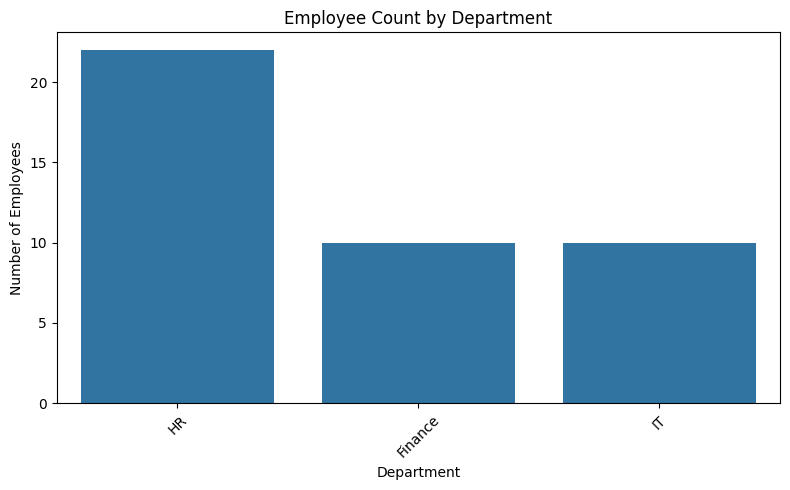

Department chart saved successfully!


In [62]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Department")

plt.title("Employee Count by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("Visualizations/department_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

print("Department chart saved successfully!")

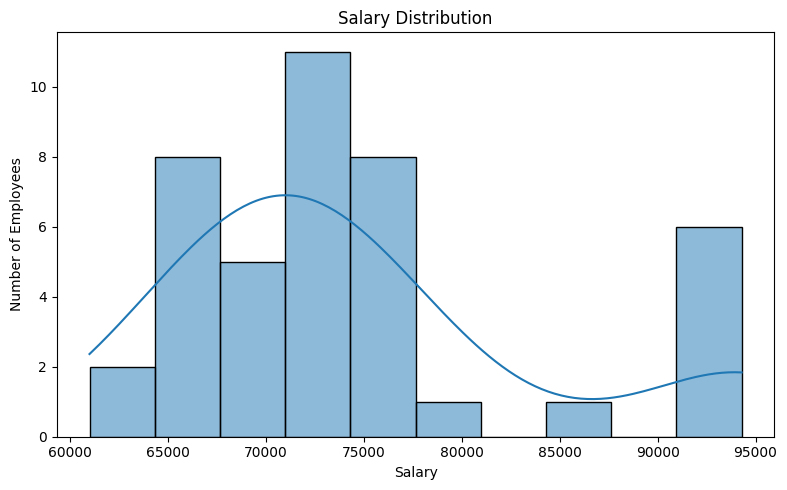

Salary chart saved successfully!


In [63]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Salary", bins=10, kde=True)

plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Number of Employees")
plt.tight_layout()

plt.savefig("Visualizations/salary_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

print("Salary chart saved successfully!")

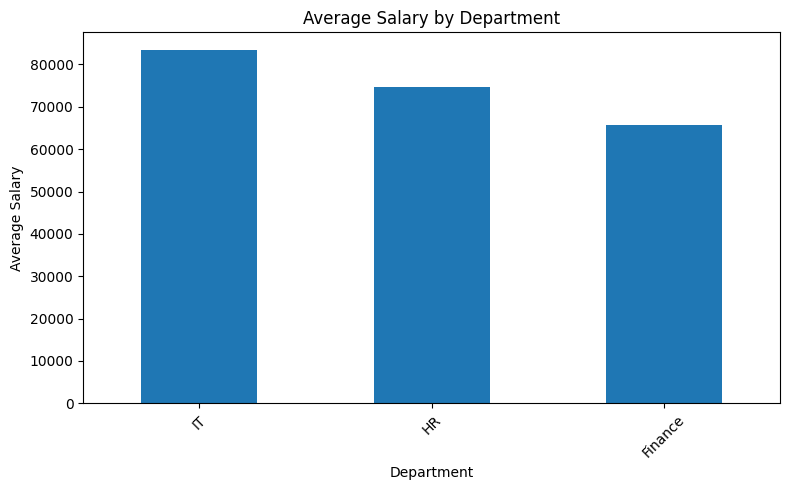

Average salary chart saved successfully!


In [64]:
avg_salary = df.groupby("Department")["Salary"].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))

avg_salary.plot(kind="bar")

plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("Visualizations/average_salary_department.png", dpi=300, bbox_inches="tight")
plt.show()

print("Average salary chart saved successfully!")

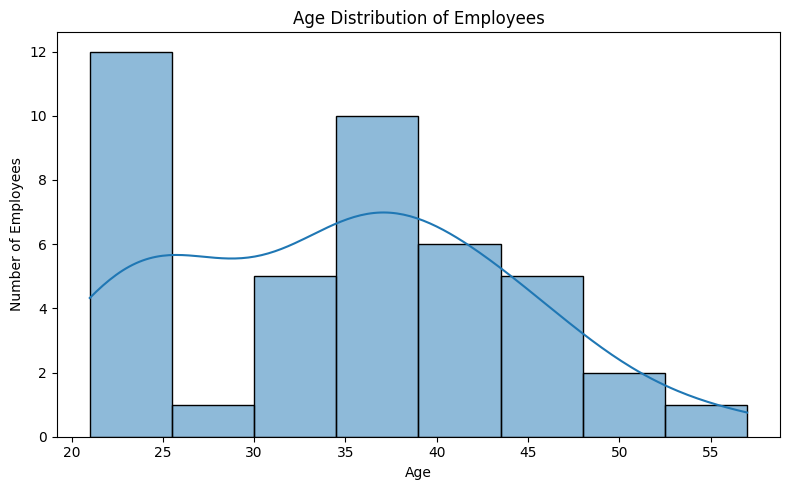

Age distribution chart saved successfully!


In [65]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Age", bins=8, kde=True)

plt.title("Age Distribution of Employees")
plt.xlabel("Age")
plt.ylabel("Number of Employees")
plt.tight_layout()

plt.savefig("Visualizations/age_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

print("Age distribution chart saved successfully!")

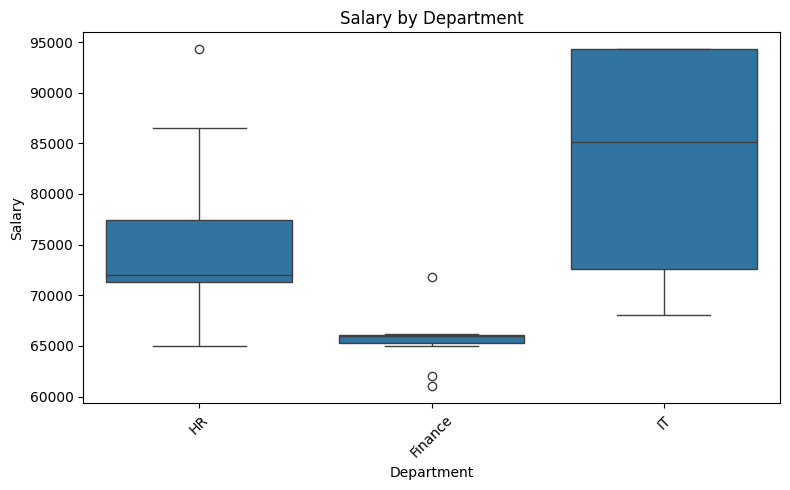

In [58]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Department", y="Salary")

plt.title("Salary by Department")
plt.xlabel("Department")
plt.ylabel("Salary")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

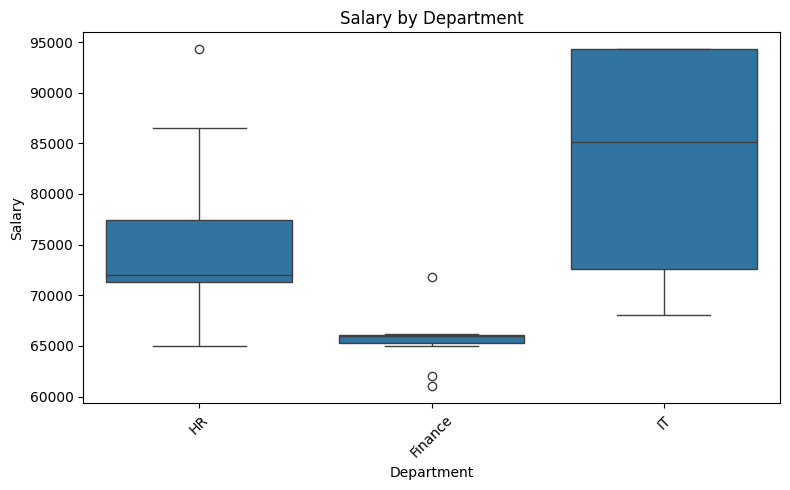

Salary by department chart saved successfully!


In [66]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Department", y="Salary")

plt.title("Salary by Department")
plt.xlabel("Department")
plt.ylabel("Salary")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("Visualizations/salary_by_department.png", dpi=300, bbox_inches="tight")
plt.show()

print("Salary by department chart saved successfully!")

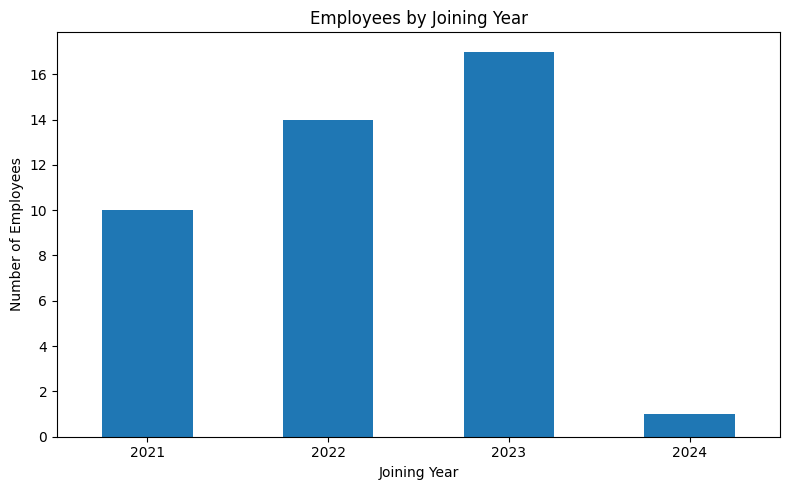

In [60]:
join_year_count = df["Join_Year"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

join_year_count.plot(kind="bar")

plt.title("Employees by Joining Year")
plt.xlabel("Joining Year")
plt.ylabel("Number of Employees")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

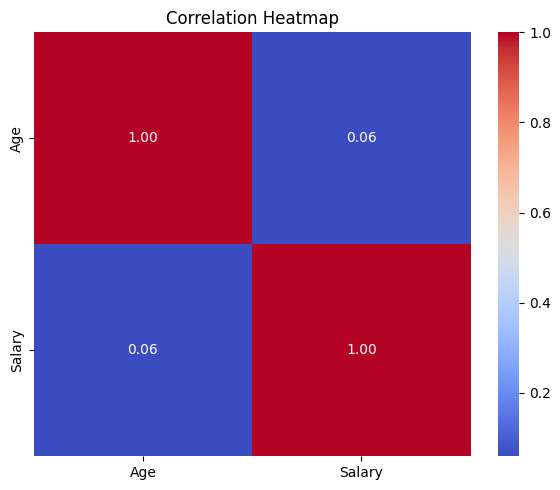

In [61]:
correlation = df[["Age", "Salary"]].corr()

plt.figure(figsize=(6, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()

plt.show()

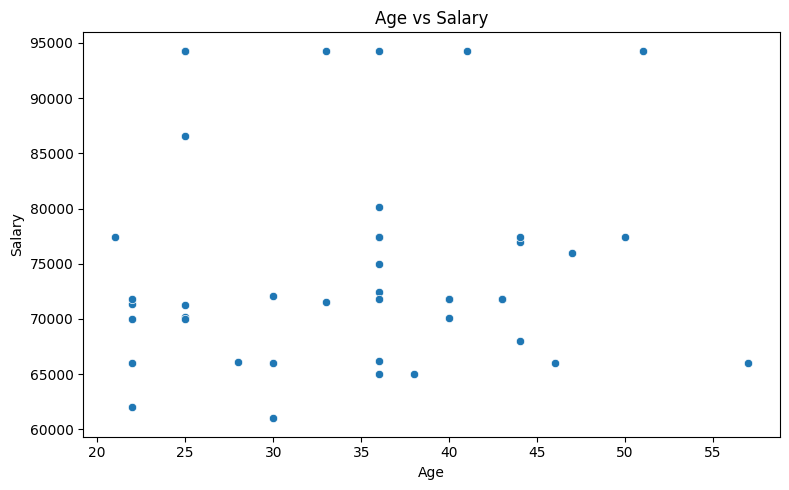

Age vs Salary chart saved successfully!


In [67]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="Age", y="Salary")

plt.title("Age vs Salary")
plt.xlabel("Age")
plt.ylabel("Salary")
plt.tight_layout()

plt.savefig("Visualizations/age_salary_scatter.png", dpi=300, bbox_inches="tight")
plt.show()

print("Age vs Salary chart saved successfully!")

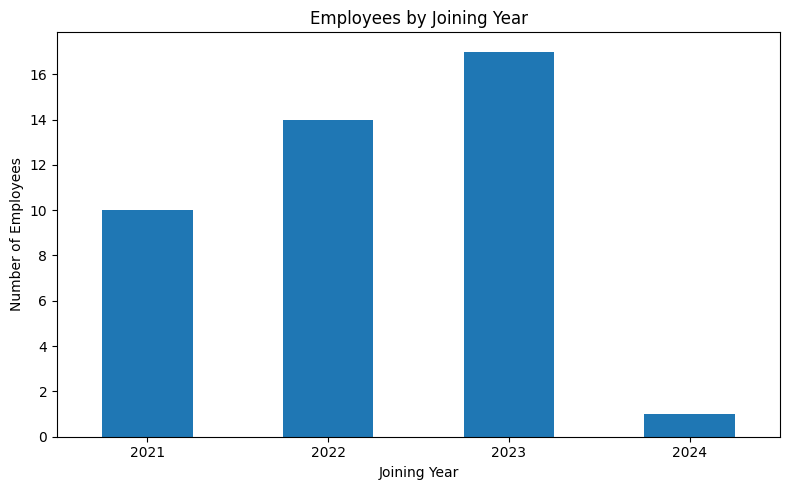

Employees by joining year chart saved successfully!


In [68]:
join_year_count = df["Join_Year"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

join_year_count.plot(kind="bar")

plt.title("Employees by Joining Year")
plt.xlabel("Joining Year")
plt.ylabel("Number of Employees")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("Visualizations/employees_joining_year.png", dpi=300, bbox_inches="tight")
plt.show()

print("Employees by joining year chart saved successfully!")

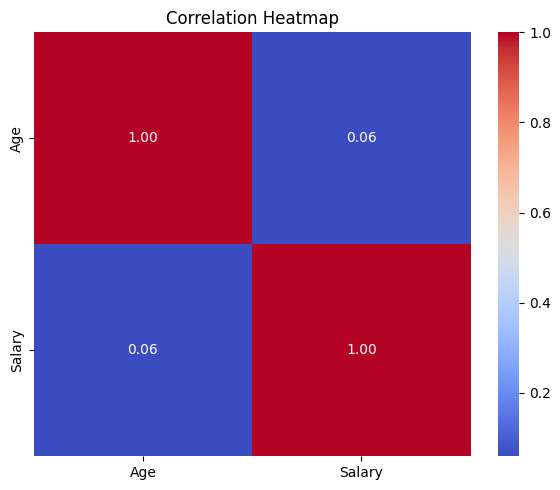

Correlation heatmap saved successfully!


In [69]:
correlation = df[["Age", "Salary"]].corr()

plt.figure(figsize=(6, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()

plt.savefig("Visualizations/correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

print("Correlation heatmap saved successfully!")